# House prices: regression

This notebook predicts the sale price of a house from `data/house_prices_demo.csv`.

Each row is one house.

- `Area_sqft` is the floor area.
- `Bedrooms` is the number of bedrooms.
- `Age_years` is the age of the house.
- `Price_lakhs` is the sale price, in lakhs of rupees. This is the number we predict.
- `House_ID` is a label. The models leave it out.

The work is in this order: load the file, clean it, plot it, then fit the models.

Run the cells from the top.


## The three scores

Every model is scored with the same three numbers. They are calculated on the **test houses**, the houses the model did not see while it was learning.

$y_i$ is the real price of house $i$. $\hat{y}_i$ is the price the model predicts. $\bar{y}$ is the average real price. $n$ is the number of test houses.

**MAE** (mean absolute error) is the average size of the miss, in lakhs. Lower is better.

$$
\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|y_i - \hat{y}_i\right|
$$

**MSE** (mean squared error) squares each miss before averaging. A large miss counts more than a small one. Lower is better.

$$
\mathrm{MSE} = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2
$$

**R²** is the share of the variation in price that the model explains. Closer to 1 is better. A value near 0 means the predictions do little better than guessing the average price for every house.

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$


## 1. Load the dataset

Pandas reads the CSV into a table. The first rows are enough to see the columns and any blank cells near the top of the file.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

# The notebook lives in Demo/, so the CSV is one folder up.
# The second path works if the notebook is run from the project folder.
path = Path("../data/house_prices_demo.csv")
if not path.exists():
    path = Path("data/house_prices_demo.csv")

houses = pd.read_csv(path)

print("Rows, columns:", houses.shape)
houses.head(10)



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

Rows, columns: (1000, 5)


,House_ID,Area_sqft,Bedrooms,Age_years,Price_lakhs
0,H001,742,3.0,16.0,63.9
1,H002,1839,3.0,13.0,110.9
2,H003,1647,2.0,8.0,90.4
3,H004,1302,4.0,19.0,96.2
4,H005,1293,3.0,23.0,75.2
5,H006,1974,NaN,0.0,134.9
6,H007,737,3.0,17.0,66.9
7,H008,1716,3.0,30.0,91.5
8,H009,922,4.0,8.0,77.8
9,H010,750,1.0,8.0,52.9


## 2. Clean the data

Two things in the raw file need a fix before any model, or any chart, uses the table.

**Blank cells.** A few values are missing, and only in `Bedrooms` and `Age_years`. A blank number can be replaced with the **mean** of that column: add up the values that are present, and divide by how many there are.

**Duplicate rows.** A few houses are copied in full. A copied row would be counted twice, so the extra copy is removed.


In [2]:
# Count blanks in every column. Area, House_ID, and Price should be zero.
print("Missing values in each column:")
print(houses.isna().sum())

# Show the rows that still need a number.
blank_rows = houses.loc[houses["Bedrooms"].isna() | houses["Age_years"].isna()]
blank_rows


Missing values in each column:
House_ID       0
Area_sqft      0
Bedrooms       5
Age_years      5
Price_lakhs    0
dtype: int64


,House_ID,Area_sqft,Bedrooms,Age_years,Price_lakhs
5,H006,1974,NaN,0.0,134.9
12,H013,1777,3.0,NaN,101.5
48,H049,1685,NaN,30.0,75.2
77,H078,963,4.0,NaN,72.2
120,H121,1303,NaN,8.0,77.8
210,H211,1018,4.0,NaN,90.7
333,H334,1928,NaN,20.0,109.1
450,H451,2137,1.0,NaN,106.2
700,H701,1433,NaN,22.0,74.9
880,H881,737,1.0,NaN,56.8


In [3]:
# duplicated() marks the extra copies. keep=False shows the original and the copy together.
print("Duplicate rows:", houses.duplicated().sum())
houses.loc[houses.duplicated(keep=False)].sort_values("House_ID")


Duplicate rows: 5


,House_ID,Area_sqft,Bedrooms,Age_years,Price_lakhs
2,H003,1647,2.0,8.0,90.4
995,H003,1647,2.0,8.0,90.4
8,H009,922,4.0,8.0,77.8
996,H009,922,4.0,8.0,77.8
15,H016,1858,2.0,3.0,96.9
997,H016,1858,2.0,3.0,96.9
30,H031,1321,1.0,9.0,72.5
998,H031,1321,1.0,9.0,72.5
60,H061,2076,4.0,5.0,118.3
999,H061,2076,4.0,5.0,118.3


In [4]:
# Keep the first copy of each repeated row, then number the rows 0, 1, 2, ... again.
houses = houses.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(houses))


Rows after removing duplicates: 995


In [5]:
# Mean of the numbers that are already filled in.
bedrooms_mean = houses["Bedrooms"].mean()
age_mean = houses["Age_years"].mean()
print("Mean bedrooms:", round(bedrooms_mean, 2))
print("Mean age (years):", round(age_mean, 2))

# Write that mean into each blank. The CSV file itself is left unchanged.
houses["Bedrooms"] = houses["Bedrooms"].fillna(bedrooms_mean)
houses["Age_years"] = houses["Age_years"].fillna(age_mean)

print("Missing values after filling:")
print(houses.isna().sum())
houses.describe()


Mean bedrooms: 2.49
Mean age (years): 15.07
Missing values after filling:
House_ID       0
Area_sqft      0
Bedrooms       0
Age_years      0
Price_lakhs    0
dtype: int64


,Area_sqft,Bedrooms,Age_years,Price_lakhs
count,995.000000,995.000000,995.000000,995.000000
mean,1404.052261,2.491919,15.071717,83.013065
std,462.539447,1.123839,8.975033,20.585802
min,607.000000,1.000000,0.000000,29.800000
25%,995.000000,1.000000,7.000000,67.900000
50%,1408.000000,2.000000,15.000000,81.000000
75%,1813.500000,4.000000,23.000000,99.000000
max,2199.000000,4.000000,30.000000,140.700000


The filled bedrooms can sit between whole numbers, because the mean is an average. Those few houses are the ones that were blank.

`describe` shows the spread of each column. Price covers a wide range of lakhs, so the task is to predict a number. That is regression.


## 3. Univariate charts

Univariate means one column at a time. A histogram counts how many houses fall in each bin.

These charts check that each column actually varies. A column that is the same for every house cannot help a regression.

Each chart is built the same way:

1. `fig, ax = plt.subplots()` makes the page and the one chart on it.
2. `ax.hist(...)` draws the bars.
3. The title and axis labels say what the bars mean.
4. `plt.show()` displays the chart.

Each chart is its own figure.


### Area

How is floor area spread across the houses?


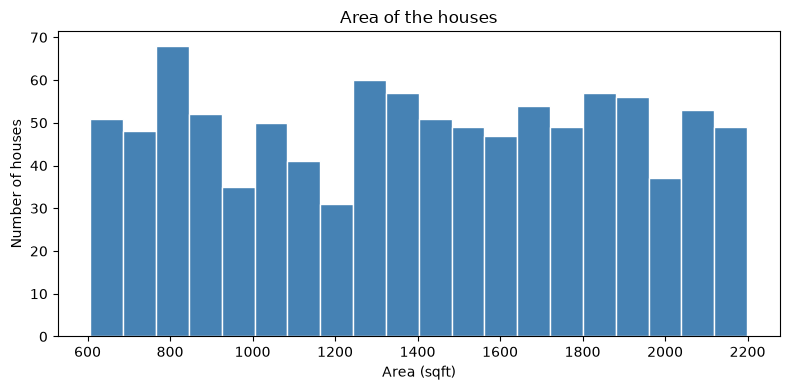

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(houses["Area_sqft"], bins=20, color="steelblue", edgecolor="white")
ax.set_title("Area of the houses")
ax.set_xlabel("Area (sqft)")
ax.set_ylabel("Number of houses")
fig.tight_layout()
plt.show()


### Bedrooms

How many bedrooms do the houses have?


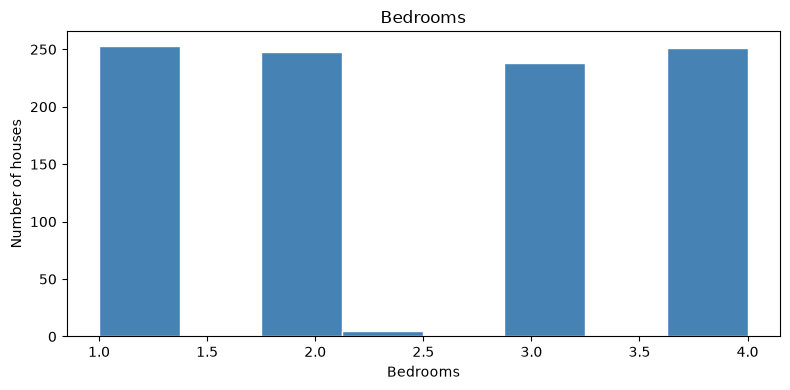

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(houses["Bedrooms"], bins=8, color="steelblue", edgecolor="white")
ax.set_title("Bedrooms")
ax.set_xlabel("Bedrooms")
ax.set_ylabel("Number of houses")
fig.tight_layout()
plt.show()


### Age

How old are the houses?


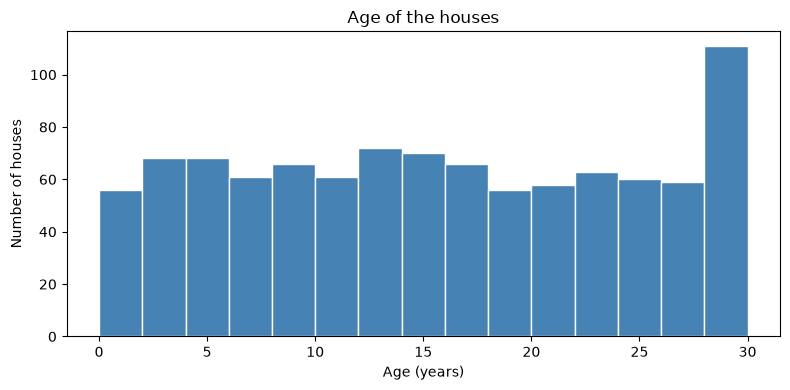

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(houses["Age_years"], bins=15, color="steelblue", edgecolor="white")
ax.set_title("Age of the houses")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of houses")
fig.tight_layout()
plt.show()


### Price

How are the sale prices spread? This is the column the models will predict.


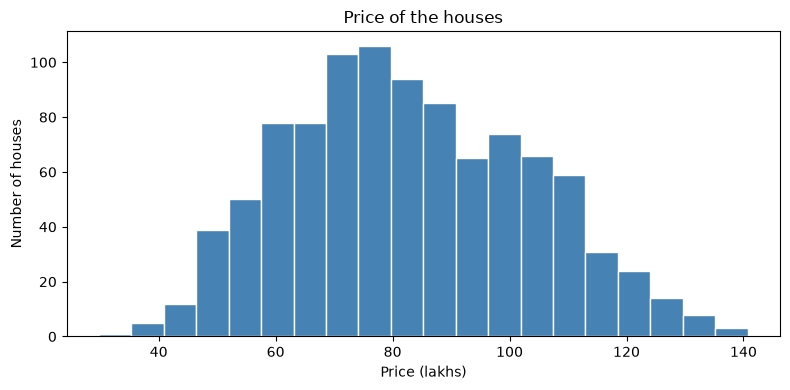

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(houses["Price_lakhs"], bins=20, color="steelblue", edgecolor="white")
ax.set_title("Price of the houses")
ax.set_xlabel("Price (lakhs)")
ax.set_ylabel("Number of houses")
fig.tight_layout()
plt.show()


Area, bedrooms, age, and price all vary from house to house. Price is a continuous number, so a regression model can aim at it. The next charts ask whether the three inputs move with that price.


## 4. Bivariate charts

Bivariate means two columns at a time. Each chart below puts one input on the horizontal axis and price on the vertical axis.

A cloud that rises or falls is a relationship a regression line can follow. The correlation is a single number for that relationship: positive when the two columns rise together, negative when one rises as the other falls. Values nearer 1 or -1 are stronger.


### Area and price

Does a larger house sell for more?


Correlation of area and price: 0.827


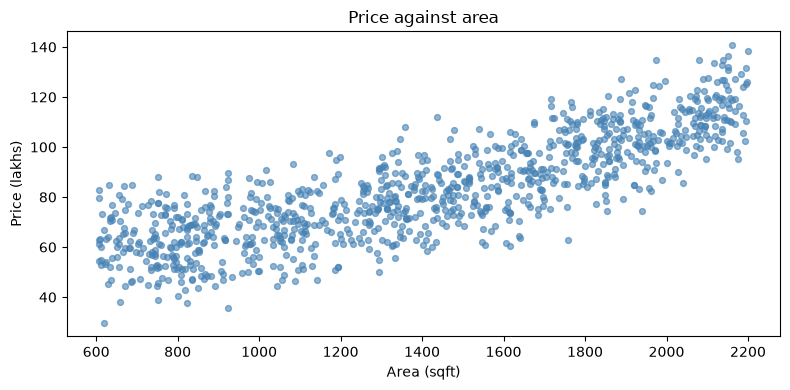

In [10]:
print("Correlation of area and price:", round(houses["Area_sqft"].corr(houses["Price_lakhs"]), 3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(houses["Area_sqft"], houses["Price_lakhs"], color="steelblue", alpha=0.6, s=18)
ax.set_title("Price against area")
ax.set_xlabel("Area (sqft)")
ax.set_ylabel("Price (lakhs)")
fig.tight_layout()
plt.show()


### Bedrooms and price

Does a house with more bedrooms sell for more?

Bedrooms take only a few values, so the points stack in columns. A few points sit between the whole numbers. Those are the rows filled with the mean.


Correlation of bedrooms and price: 0.413


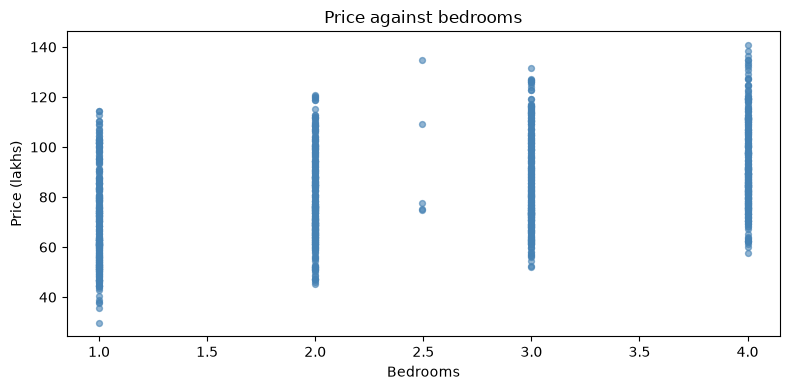

In [11]:
print("Correlation of bedrooms and price:", round(houses["Bedrooms"].corr(houses["Price_lakhs"]), 3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(houses["Bedrooms"], houses["Price_lakhs"], color="steelblue", alpha=0.6, s=18)
ax.set_title("Price against bedrooms")
ax.set_xlabel("Bedrooms")
ax.set_ylabel("Price (lakhs)")
fig.tight_layout()
plt.show()


### Age and price

Does an older house sell for less?


Correlation of age and price: -0.317


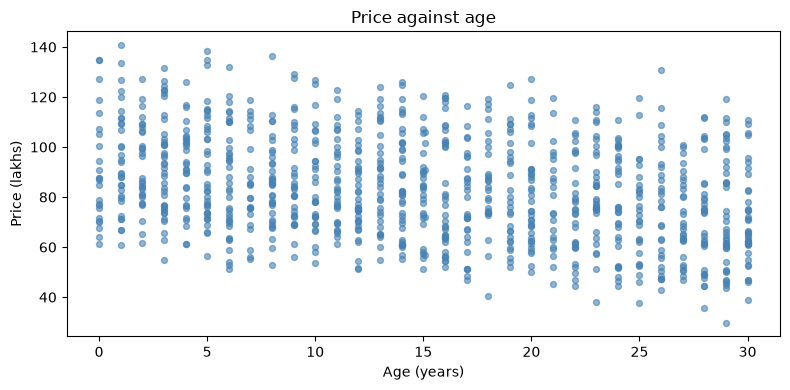

In [12]:
print("Correlation of age and price:", round(houses["Age_years"].corr(houses["Price_lakhs"]), 3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(houses["Age_years"], houses["Price_lakhs"], color="steelblue", alpha=0.6, s=18)
ax.set_title("Price against age")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Price (lakhs)")
fig.tight_layout()
plt.show()


Area and price rise together, and that is the strongest of the three links. More bedrooms also line up with a higher price. Age moves the other way: older houses line up with a lower price.

A model that draws a line, or a gentle curve, through these clouds has something real to learn. Regression is a reasonable next step.


## 5. Multivariate charts

Multivariate means more than two columns at once.

Each chart keeps area and price, and adds a third column as the color of the point. If houses with the same area still sit higher or lower because of that color, the third column carries information the model should use.


### Area, price, and bedrooms

At a similar area, do extra bedrooms still raise the price?


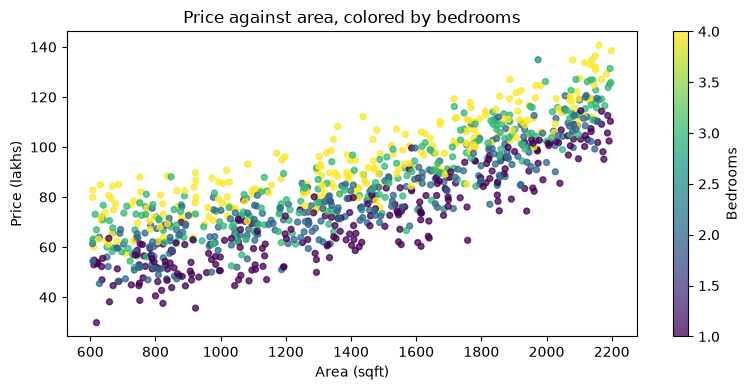

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
points = ax.scatter(
    houses["Area_sqft"],
    houses["Price_lakhs"],
    c=houses["Bedrooms"],
    cmap="viridis",
    alpha=0.75,
    s=18,
)
fig.colorbar(points, ax=ax, label="Bedrooms")
ax.set_title("Price against area, colored by bedrooms")
ax.set_xlabel("Area (sqft)")
ax.set_ylabel("Price (lakhs)")
fig.tight_layout()
plt.show()


### Area, price, and age

At a similar area, do newer houses still sell for more?


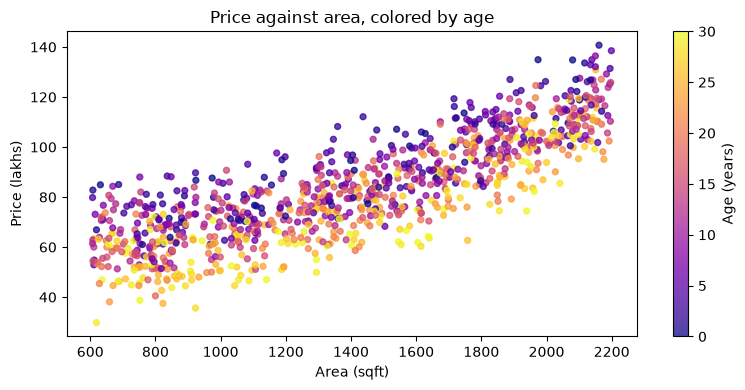

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
points = ax.scatter(
    houses["Area_sqft"],
    houses["Price_lakhs"],
    c=houses["Age_years"],
    cmap="plasma",
    alpha=0.75,
    s=18,
)
fig.colorbar(points, ax=ax, label="Age (years)")
ax.set_title("Price against area, colored by age")
ax.set_xlabel("Area (sqft)")
ax.set_ylabel("Price (lakhs)")
fig.tight_layout()
plt.show()


The upward cloud is still there, and the color is arranged through it. Bedrooms and age still matter once area is taken into account. The three inputs can go into one regression together.


## 6. Linear regression

Linear regression fits one weight per input:

`price = intercept + (area weight × area) + (bedroom weight × bedrooms) + (age weight × age)`

A positive weight raises the predicted price. A negative weight lowers it. The weights are chosen on the training houses.

The table is split once here. 80% of the houses are for training. 20% are held out as the test set. Every model below uses this same split, so the three scores can be compared.

The score functions are imported in this block. Later models call the same three.


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# House_ID stays out. It does not describe the house.
features = ["Area_sqft", "Bedrooms", "Age_years"] # x1, x2, x3
target = "Price_lakhs" # y

X = houses[features]
y = houses[target]

# random_state keeps the same houses in the test set on every run.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training houses:", len(X_train))
print("Test houses:", len(X_test))

results = []

def print_scores(model_name, y_true, y_pred):
    # MAE, MSE, and R2. The formulas are at the top of the notebook.
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(model_name)
    print("MAE:", round(mae, 3))
    print("MSE:", round(mse, 3))
    print("R2:", round(r2, 3))
    results.append({"Model": model_name, "MAE": mae, "MSE": mse, "R2": r2})

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)
print_scores("Linear regression", y_test, pred_linear)

print("Intercept:", round(linear_model.intercept_, 2))
print("Weight for Area_sqft:", round(linear_model.coef_[0], 4))
print("Weight for Bedrooms:", round(linear_model.coef_[1], 4))
print("Weight for Age_years:", round(linear_model.coef_[2], 4))


Training houses: 796
Test houses: 199
Linear regression
MAE: 4.439
MSE: 32.172
R2: 0.923
Intercept: 25.15
Weight for Area_sqft: 0.036
Weight for Bedrooms: 6.8028
Weight for Age_years: -0.6447


In [16]:
# find hte price of house haing 5 bedroom, 200 sq ft, 4 years old

price = linear_model.predict([[200, 5, 4]])
# price = 0.036(area) + 6.8028(bedrooms)  - 0.6447(age) + 25.15 
# y = m1 * x1 + m2 * x2 + m3 * x3 + c
print(price)

[63.78821385]


/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Read the signs against the scatter charts. Area and bedrooms should have a positive weight. Age should have a negative weight.

The next chart is the test houses only. The horizontal axis is the real price. The vertical axis is the predicted price. The gray line is a perfect prediction. Points close to that line are houses the model priced well.


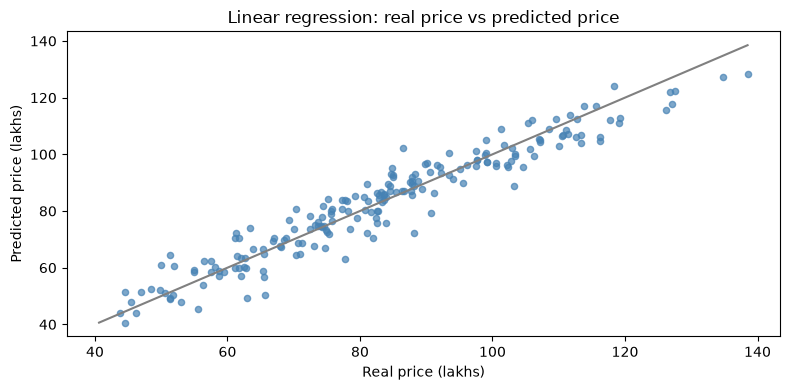

In [16]:
low = min(y_test.min(), pred_linear.min())
high = max(y_test.max(), pred_linear.max())

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(y_test, pred_linear, color="steelblue", alpha=0.7, s=20)
ax.plot([low, high], [low, high], color="gray")
ax.set_title("Linear regression: real price vs predicted price")
ax.set_xlabel("Real price (lakhs)")
ax.set_ylabel("Predicted price (lakhs)")
fig.tight_layout()
plt.show()


## 7. Ridge regression

Ridge regression is linear regression with a penalty. The penalty is `alpha` times the sum of the squared weights. A larger `alpha` pulls every weight toward 0, so one input cannot dominate the price.

The inputs are scaled first. Area is in the thousands, while bedrooms are 1 to 4. Scaling puts them on a similar range before the penalty is applied.

`alpha=1` is a small penalty. The three scores use the same test houses as the linear model.


In [17]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

# Area is in the thousands and bedrooms are 1 to 4.
# Scaling puts each input on a similar range so the penalty treats the weights fairly.
ridge_scaler = StandardScaler()
X_train_scaled = ridge_scaler.fit_transform(X_train)
X_test_scaled = ridge_scaler.transform(X_test)

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
pred_ridge = ridge_model.predict(X_test_scaled)
print_scores("Ridge regression", y_test, pred_ridge)

# These weights are for the scaled inputs, not for one raw square foot or one bedroom.
print("Intercept:", round(ridge_model.intercept_, 2))
print("Weight for Area_sqft:", round(ridge_model.coef_[0], 4))
print("Weight for Bedrooms:", round(ridge_model.coef_[1], 4))
print("Weight for Age_years:", round(ridge_model.coef_[2], 4))


Ridge regression
MAE: 4.439
MSE: 32.18
R2: 0.923
Intercept: 82.98
Weight for Area_sqft: 16.7226
Weight for Bedrooms: 7.593
Weight for Age_years: -5.7951


## 8. Lasso regression

Lasso regression is linear regression with a different penalty. The penalty is `alpha` times the sum of the absolute weights. Lasso can shrink a weight all the way to 0, and a weight of 0 drops that input from the prediction.

The inputs are scaled the same way as for ridge. `alpha=1` matches the ridge model, so the three scores can be compared on the same test houses.


In [18]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Same scaling as ridge, so the two penalties can be compared.
lasso_scaler = StandardScaler()
X_train_scaled = lasso_scaler.fit_transform(X_train)
X_test_scaled = lasso_scaler.transform(X_test)

lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train_scaled, y_train)
pred_lasso = lasso_model.predict(X_test_scaled)
print_scores("Lasso regression", y_test, pred_lasso)

# These weights are for the scaled inputs. A weight of 0 means that input was dropped.
print("Intercept:", round(lasso_model.intercept_, 2))
print("Weight for Area_sqft:", round(lasso_model.coef_[0], 4))
print("Weight for Bedrooms:", round(lasso_model.coef_[1], 4))
print("Weight for Age_years:", round(lasso_model.coef_[2], 4))


Lasso regression
MAE: 4.675
MSE: 35.866
R2: 0.914
Intercept: 82.98
Weight for Area_sqft: 15.7904
Weight for Bedrooms: 6.6787
Weight for Age_years: -4.8547


## 9. Polynomial regression, degrees 2 to 10

Polynomial regression builds extra columns from the three inputs: powers and products, up to a chosen degree. Degree 2 can bend a little. Degree 10 can bend a lot.

The next cell fits degree 2 on its own, so the three scores are easy to read for one curve. The cell after that loops from degree 2 to 10 on the same training houses, and scores each degree on the same test houses.

Two steps keep the fit under control.

- The inputs are scaled first. Area is in the thousands, and a 10th power of a raw area would be an enormous number.
- Each degree is then fit with **Ridge** regression: linear regression plus a small penalty (`alpha=1`). High powers are almost repeats of the original columns. Without the penalty the predicted prices explode and the scores stop meaning anything. The penalty keeps the prices on a sensible scale, so the chart can show the best degree.

The scaled columns are a new table. `X_train` itself stays as it was, for the models that come later.

A higher degree fits the training houses a little more tightly. Judge the degree by the test scores. Small ups and downs from one degree to the next can happen. The best degree is the one with the highest test R² and the lowest test MAE and MSE.


In [19]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Degree 2 only. The next cell repeats this for every degree from 2 to 10.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# alpha=1 is the same small penalty used in the loop below.
poly_model = Ridge(alpha=1.0)
poly_model.fit(X_train_poly, y_train)
pred_poly = poly_model.predict(X_test_poly)

mae = mean_absolute_error(y_test, pred_poly)
mse = mean_squared_error(y_test, pred_poly)
r2 = r2_score(y_test, pred_poly)
print("Polynomial (degree 2)")
print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("R2:", round(r2, 3))


Polynomial (degree 2)
MAE: 4.02
MSE: 26.719
R2: 0.936


In [20]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

degrees = []
test_mae = []
test_mse = []
test_r2 = []
train_r2 = []

for degree in range(2, 11):
    # Fit the scaler on the training houses only, then apply it to the test houses.
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Powers and products up to this degree.
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train_scaled)
    X_test_poly = poly.transform(X_test_scaled)

    # alpha=1 is the penalty that keeps high degrees from exploding.
    poly_model = Ridge(alpha=1.0)
    poly_model.fit(X_train_poly, y_train)
    pred_poly = poly_model.predict(X_test_poly)

    mae = mean_absolute_error(y_test, pred_poly)
    mse = mean_squared_error(y_test, pred_poly)
    r2 = r2_score(y_test, pred_poly)
    r2_train = r2_score(y_train, poly_model.predict(X_train_poly))

    degrees.append(degree)
    test_mae.append(mae)
    test_mse.append(mse)
    test_r2.append(r2)
    train_r2.append(r2_train)

    print(
        "Degree", degree,
        " MAE:", round(mae, 3),
        " MSE:", round(mse, 3),
        " R2:", round(r2, 3),
        " Train R2:", round(r2_train, 3),
    )

degree_scores = pd.DataFrame({
    "Degree": degrees,
    "MAE": test_mae,
    "MSE": test_mse,
    "R2": test_r2,
    "Train R2": train_r2,
})

best_pos = test_r2.index(max(test_r2))
best_degree = degrees[best_pos]
print("Best degree by test R2:", best_degree)
print("Degree with the lowest test MAE:", degrees[test_mae.index(min(test_mae))])
print("Degree with the lowest test MSE:", degrees[test_mse.index(min(test_mse))])

# Keep the best degree for the comparison at the end.
results.append({
    "Model": f"Polynomial (degree {best_degree})",
    "MAE": test_mae[best_pos],
    "MSE": test_mse[best_pos],
    "R2": test_r2[best_pos],
})

degree_scores.round(3)


Degree 2  MAE: 4.02  MSE: 26.719  R2: 0.936  Train R2: 0.939
Degree 3  MAE: 4.064  MSE: 27.339  R2: 0.934  Train R2: 0.94
Degree 4  MAE: 4.074  MSE: 27.261  R2: 0.934  Train R2: 0.94
Degree 5  MAE: 4.181  MSE: 29.125  R2: 0.93  Train R2: 0.942
Degree 6  MAE: 4.201  MSE: 29.199  R2: 0.93  Train R2: 0.943
Degree 7  MAE: 4.168  MSE: 29.314  R2: 0.929  Train R2: 0.946
Degree 8  MAE: 4.224  MSE: 30.462  R2: 0.927  Train R2: 0.948
Degree 9  MAE: 4.427  MSE: 32.596  R2: 0.922  Train R2: 0.95
Degree 10  MAE: 4.723  MSE: 38.941  R2: 0.906  Train R2: 0.952
Best degree by test R2: 2
Degree with the lowest test MAE: 2
Degree with the lowest test MSE: 2


,Degree,MAE,MSE,R2,Train R2
0,2,4.020,26.719,0.936,0.939
1,3,4.064,27.339,0.934,0.940
2,4,4.074,27.261,0.934,0.940
3,5,4.181,29.125,0.930,0.942
4,6,4.201,29.199,0.930,0.943
5,7,4.168,29.314,0.929,0.946
6,8,4.224,30.462,0.927,0.948
7,9,4.427,32.596,0.922,0.950
8,10,4.723,38.941,0.906,0.952


The next three charts show those scores, one chart per score. The dashed line marks the degree with the highest test R².

On the MAE chart and the MSE chart, the best degree is the low point. On the R² chart, the best degree is the high point. In the table, train R² creeps up as the degree rises, while the test scores get worse after the best degree.


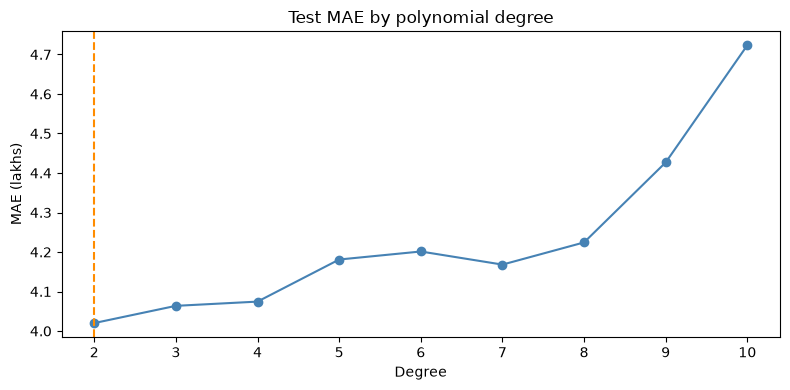

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degrees, test_mae, marker="o", color="steelblue")
ax.axvline(best_degree, color="darkorange", linestyle="--")
ax.set_title("Test MAE by polynomial degree")
ax.set_xlabel("Degree")
ax.set_ylabel("MAE (lakhs)")
ax.set_xticks(degrees)
fig.tight_layout()
plt.show()


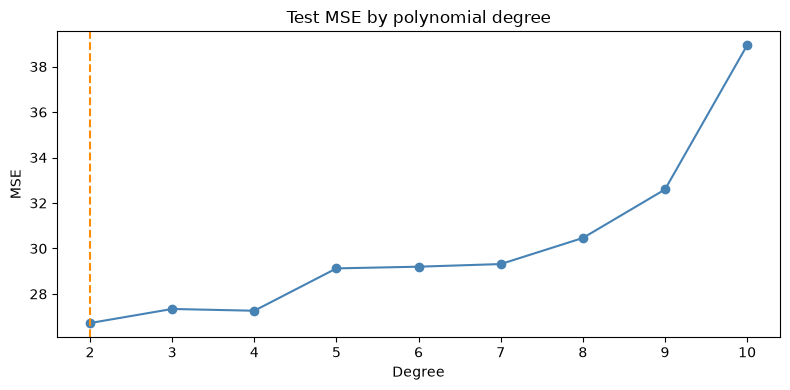

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degrees, test_mse, marker="o", color="steelblue")
ax.axvline(best_degree, color="darkorange", linestyle="--")
ax.set_title("Test MSE by polynomial degree")
ax.set_xlabel("Degree")
ax.set_ylabel("MSE")
ax.set_xticks(degrees)
fig.tight_layout()
plt.show()


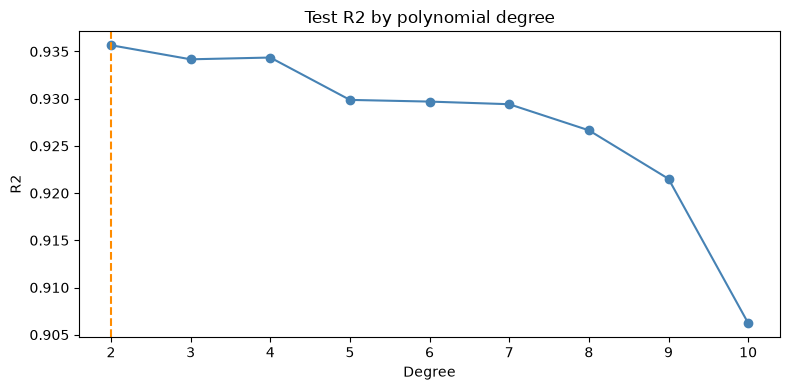

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degrees, test_r2, marker="o", color="steelblue")
ax.axvline(best_degree, color="darkorange", linestyle="--")
ax.set_title("Test R2 by polynomial degree")
ax.set_xlabel("Degree")
ax.set_ylabel("R2")
ax.set_xticks(degrees)
fig.tight_layout()
plt.show()


## 10. Decision tree regression

A decision tree asks a chain of yes/no questions, such as whether area is above a cut or age is below a cut. Each house ends in a leaf, and the leaf's prediction is the average price of the training houses that landed there.

`max_depth=6` stops the tree after six questions. A deeper tree can memorize the training houses and then miss the test houses.


In [24]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=6, random_state=42)
tree_model.fit(X_train, y_train)
pred_tree = tree_model.predict(X_test)
print_scores("Decision tree", y_test, pred_tree)


Decision tree
MAE: 5.571
MSE: 49.621
R2: 0.881


## 11. Random forest regression

A random forest grows many decision trees. Each tree sees a random sample of the training houses. The prediction is the average of the trees.

Averaging keeps a single odd tree from dominating the price. `n_estimators=100` is the number of trees. `max_depth=8` limits how long each tree is.


In [25]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    random_state=42,
)
forest_model.fit(X_train, y_train)
pred_forest = forest_model.predict(X_test)
print_scores("Random forest", y_test, pred_forest)


Random forest
MAE: 4.405
MSE: 31.929
R2: 0.923


## 12. Gradient boosting regression

Gradient boosting also uses trees, built one after another. Each new tree focuses on the houses the earlier trees priced badly. The final prediction adds those trees together.

`learning_rate=0.1` keeps each new tree's correction small. `n_estimators=100` is the number of trees. `max_depth=3` keeps each tree short.


In [26]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
)
gbr_model.fit(X_train, y_train)
pred_gbr = gbr_model.predict(X_test)
print_scores("Gradient boosting", y_test, pred_gbr)


Gradient boosting
MAE: 4.459
MSE: 33.031
R2: 0.92


## 13. XGBoost regression

XGBoost is a gradient boosting method with its own implementation. It builds the same kind of sequence: each new tree works on the remaining error.

The settings match the previous model (100 trees, learning rate 0.1, depth 3) so the two scores are comparable. `reg:squarederror` tells XGBoost that the target is a number and the loss is squared error, the same idea as MSE.


In [27]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    objective="reg:squarederror",
    random_state=42,
)
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)
print_scores("XGBoost", y_test, pred_xgb)


XGBoost
MAE: 4.491
MSE: 33.118
R2: 0.92


## 14. Support vector regression

Support vector regression (SVR) looks for a function with a tube around it. Misses smaller than `epsilon` sit inside the tube and are treated as close enough. `C` controls how hard the model tries to stay inside that tube. The RBF kernel lets the function curve.

SVR uses distances between houses. Area is in the thousands and bedrooms are 1 to 4, so area would dominate the distance. Scaling puts the three inputs on a similar range. The scaler is fit on the training houses only.


In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

svr_scaler = StandardScaler()
X_train_scaled = svr_scaler.fit_transform(X_train)
X_test_scaled = svr_scaler.transform(X_test)

# epsilon is in lakhs. Misses smaller than 2 lakhs sit inside the tube.
svr_model = SVR(kernel="rbf", C=10, epsilon=2)
svr_model.fit(X_train_scaled, y_train)
pred_svr = svr_model.predict(X_test_scaled)
print_scores("SVR", y_test, pred_svr)


SVR
MAE: 4.125
MSE: 27.798
R2: 0.933


## 15. Compare the models

The table collects the test MAE, test MSE, and test R² for every model. The polynomial row is the best degree from the charts above.

The three bar charts show the same numbers, one chart per score. A shorter bar is better for MAE and MSE. A taller bar is better for R².


In [29]:
comparison = pd.DataFrame(results)
comparison["MAE"] = comparison["MAE"].round(3)
comparison["MSE"] = comparison["MSE"].round(3)
comparison["R2"] = comparison["R2"].round(3)
comparison


,Model,MAE,MSE,R2
0,Linear regression,4.439,32.172,0.923
1,Ridge regression,4.439,32.180,0.923
2,Lasso regression,4.675,35.866,0.914
3,Polynomial (degree 2),4.020,26.719,0.936
4,Decision tree,5.571,49.621,0.881
5,Random forest,4.405,31.929,0.923
6,Gradient boosting,4.459,33.031,0.920
7,XGBoost,4.491,33.118,0.920
8,SVR,4.125,27.798,0.933


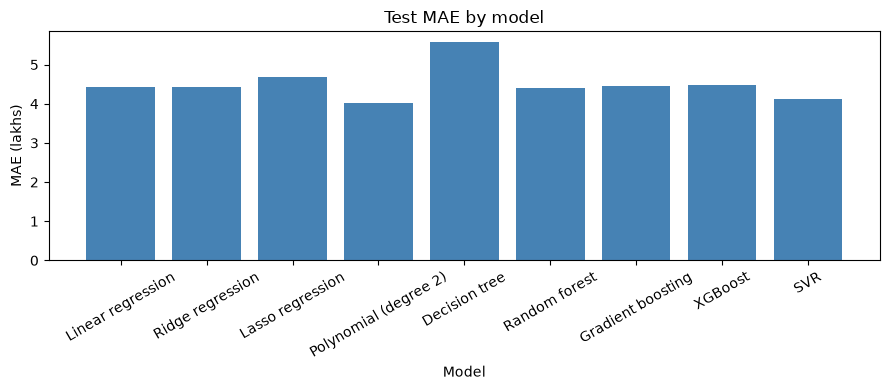

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison["Model"], comparison["MAE"], color="steelblue")
ax.set_title("Test MAE by model")
ax.set_xlabel("Model")
ax.set_ylabel("MAE (lakhs)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


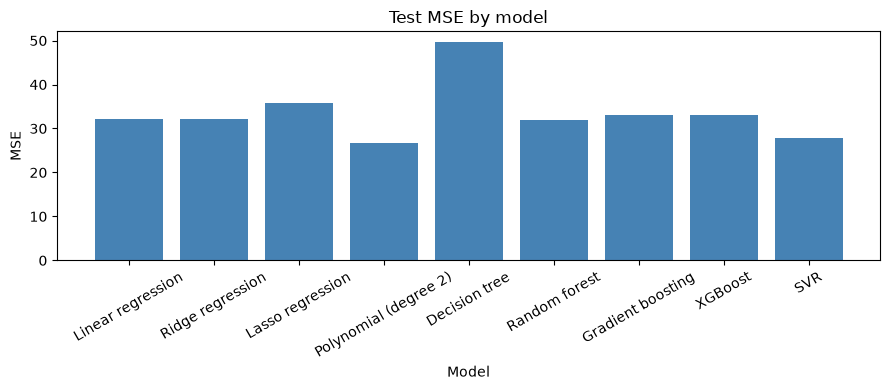

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison["Model"], comparison["MSE"], color="steelblue")
ax.set_title("Test MSE by model")
ax.set_xlabel("Model")
ax.set_ylabel("MSE")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


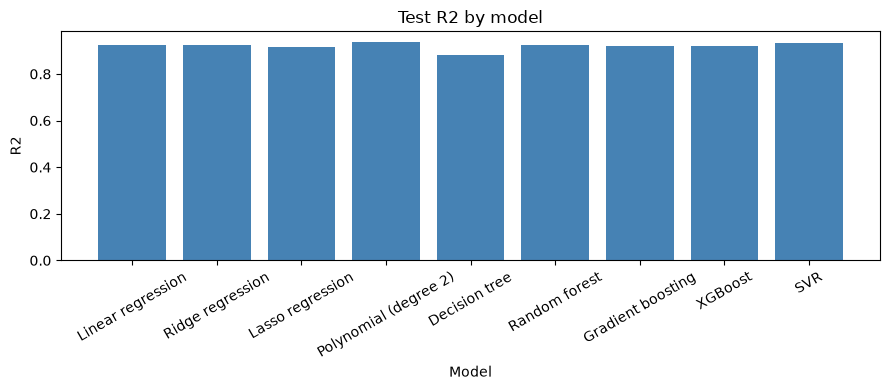

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison["Model"], comparison["R2"], color="steelblue")
ax.set_title("Test R2 by model")
ax.set_xlabel("Model")
ax.set_ylabel("R2")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


In [33]:
best_r2_row = comparison["R2"].idxmax()
best_mae_row = comparison["MAE"].idxmin()
best_mse_row = comparison["MSE"].idxmin()

print("Highest test R2:", comparison.loc[best_r2_row, "Model"])
print("Lowest test MAE:", comparison.loc[best_mae_row, "Model"])
print("Lowest test MSE:", comparison.loc[best_mse_row, "Model"])


Highest test R2: Polynomial (degree 2)
Lowest test MAE: Polynomial (degree 2)
Lowest test MSE: Polynomial (degree 2)


## Takeaways

- The raw file has blank cells in `Bedrooms` and `Age_years` only. Each blank was filled with that column's mean.
- A few rows were exact copies. `drop_duplicates` removed the extra copies.
- The univariate charts show that price and the three inputs all vary.
- The bivariate charts show area and bedrooms rising with price, and age falling as price rises. That is enough structure for a regression.
- The multivariate charts show that bedrooms and age still shift the price when area is held in view, so the model can use all three inputs.
- Among polynomial degrees 2 to 10, the best degree is the low point of the MAE and MSE charts and the high point of the R² chart. Higher degrees score worse on the test houses.
- Read the last three bars together with the table. Lower MAE, lower MSE, and higher R² mark the stronger model on the houses it did not train on.
